# SQL-Powered Electricity Demand Visualisations

This notebook demonstrates the integration of SQL and Python to analyse electricity demand in Great Britain using NESO's 2024 Historic Demand Data.

SQL queries are executed against a SQLite database, with the results imported into pandas and visualised using Matplotlib.

## 1. Setup and Database Connection

The analysis begins by importing the required libraries and establishing a connection to the SQLite database created from the original NESO dataset.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

DB_PATH = "../data/electricity_demand.db"

conn = sqlite3.connect(DB_PATH)

In [2]:
query = """
SELECT COUNT(*) AS total_records
FROM electricity_demand;
"""

pd.read_sql_query(query, conn)

,total_records
0,17568


## 2. Daily Demand and 7-Day Moving Average

This analysis uses SQL to calculate daily average National Demand and a trailing 7-day moving average. The results are imported into pandas and visualised to examine short-term fluctuations and broader demand trends during 2024.

In [3]:
moving_avg_query = """
WITH daily_demand AS (
    SELECT
        DATE(SETTLEMENT_DATE) AS demand_date,
        AVG(ND) AS avg_daily_demand_mw
    FROM electricity_demand
    GROUP BY DATE(SETTLEMENT_DATE)
)
SELECT
    demand_date,
    avg_daily_demand_mw,
    AVG(avg_daily_demand_mw) OVER (
        ORDER BY demand_date
        ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
    ) AS moving_avg_7day_mw
FROM daily_demand
ORDER BY demand_date;
"""

moving_avg_df = pd.read_sql_query(moving_avg_query, conn)

moving_avg_df.head()

,demand_date,avg_daily_demand_mw,moving_avg_7day_mw
0,2024-01-01,25270.187500,25270.187500
1,2024-01-02,29282.125000,27276.156250
2,2024-01-03,30733.437500,28428.583333
3,2024-01-04,32170.625000,29364.093750
4,2024-01-05,32196.083333,29930.491667


In [4]:
moving_avg_df["demand_date"] = pd.to_datetime(
    moving_avg_df["demand_date"]
)

moving_avg_df.dtypes

demand_date            datetime64[us]
avg_daily_demand_mw           float64
moving_avg_7day_mw            float64
dtype: object

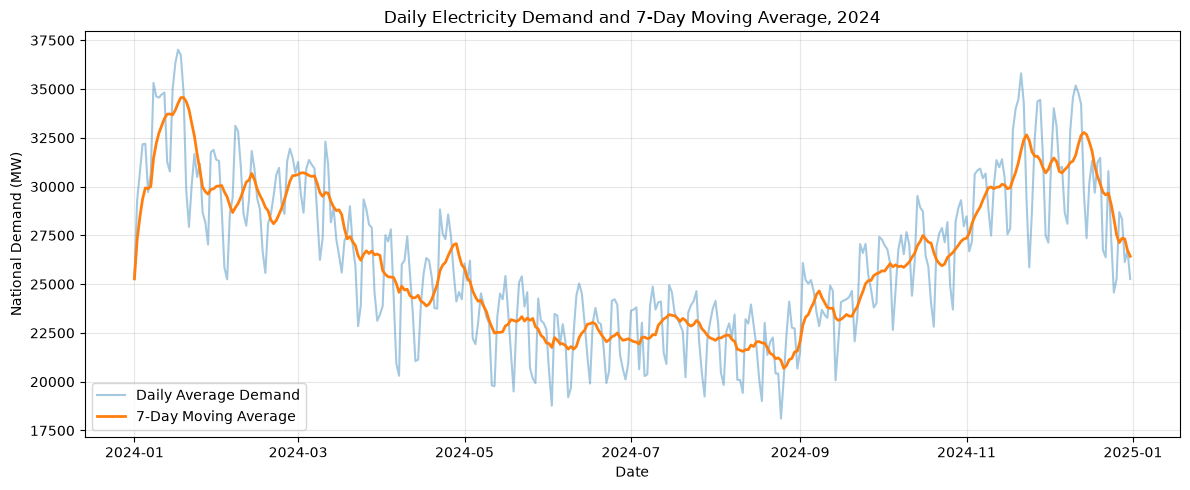

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(
    moving_avg_df["demand_date"],
    moving_avg_df["avg_daily_demand_mw"],
    label="Daily Average Demand",
    alpha=0.4
)

plt.plot(
    moving_avg_df["demand_date"],
    moving_avg_df["moving_avg_7day_mw"],
    label="7-Day Moving Average",
    linewidth=2
)

plt.title("Daily Electricity Demand and 7-Day Moving Average, 2024")
plt.xlabel("Date")
plt.ylabel("National Demand (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "../outputs/figures/daily_demand_7day_moving_average.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**Finding:** Daily average National Demand fluctuated considerably throughout 2024, while the 7-day moving average produced a smoother representation of the underlying demand pattern. Both series showed higher demand during the winter months and lower demand during summer, consistent with the seasonal patterns identified in the earlier analysis.

The moving average reduces short-term variability but does not eliminate it or explain its causes. It provides a useful descriptive measure for identifying broader demand trends.

## 3. Monthly Electricity Demand Variability

This analysis uses SQL to calculate the minimum, average and maximum half-hourly National Demand for each month of 2024.

Comparing these measures helps reveal both seasonal differences and the range of demand levels observed within each month.

In [7]:
monthly_query = """
SELECT
    strftime('%m', SETTLEMENT_DATE) AS month,
    MIN(ND) AS min_demand_mw,
    AVG(ND) AS avg_demand_mw,
    MAX(ND) AS max_demand_mw
FROM electricity_demand
GROUP BY strftime('%m', SETTLEMENT_DATE)
ORDER BY month;
"""

monthly_df = pd.read_sql_query(monthly_query, conn)

monthly_df

,month,min_demand_mw,avg_demand_mw,max_demand_mw
0,01,18079,31808.836022,45202
1,02,17883,29526.081897,41216
2,03,18162,27902.240242,40749
3,04,15871,25210.959028,34206
4,05,15894,23120.840054,30715
5,06,15302,22103.075000,29605
6,07,16277,22822.988575,30261
7,08,15071,21699.211694,29061
8,09,15904,24307.613889,33990
9,10,16141,26696.029530,37431


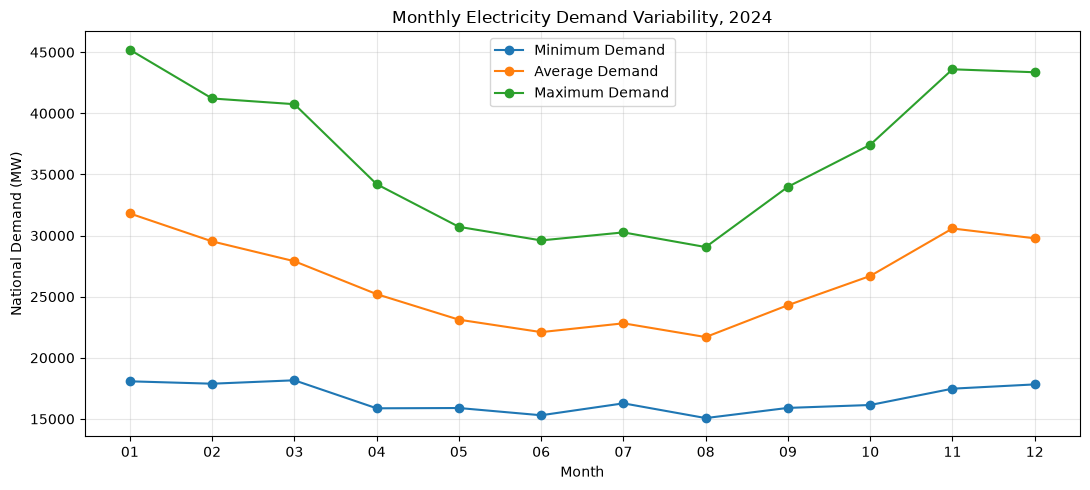

In [8]:
plt.figure(figsize=(11, 5))

plt.plot(
    monthly_df["month"],
    monthly_df["min_demand_mw"],
    marker="o",
    label="Minimum Demand"
)

plt.plot(
    monthly_df["month"],
    monthly_df["avg_demand_mw"],
    marker="o",
    label="Average Demand"
)

plt.plot(
    monthly_df["month"],
    monthly_df["max_demand_mw"],
    marker="o",
    label="Maximum Demand"
)

plt.title("Monthly Electricity Demand Variability, 2024")
plt.xlabel("Month")
plt.ylabel("National Demand (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/monthly_demand_variability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Finding:** January recorded the widest range between minimum and maximum half-hourly National Demand, indicating a substantial difference between the lowest and highest demand observations during that month.

Although average and maximum demand generally followed a similar seasonal pattern, their changes were not always proportional. For example, average demand declined noticeably between February and March, while maximum demand decreased only slightly.

This highlights an important distinction between typical electricity demand and peak demand. Even when average demand decreases, relatively high demand peaks may persist, which is relevant for electricity system capacity planning.

**Limitation:** The minimum–maximum range is sensitive to extreme observations and does not, by itself, describe the overall variability or distribution of demand.

In [9]:
monthly_df["demand_range_mw"] = (
    monthly_df["max_demand_mw"]
    - monthly_df["min_demand_mw"]
)

monthly_df[
    ["month", "demand_range_mw"]
].sort_values(
    "demand_range_mw",
    ascending=False
)

,month,demand_range_mw
0,01,27123
10,11,26126
11,12,25535
1,02,23333
2,03,22587
9,10,21290
3,04,18335
8,09,18086
4,05,14821
5,06,14303


## 4. Key Findings and Conclusions

SQL-based analysis of Great Britain's 2024 electricity demand revealed the following:

1. **Seasonal demand patterns:** Electricity demand was generally higher during winter and lower during summer.

2. **Short-term fluctuations:** The 7-day moving average smoothed daily demand fluctuations, making broader seasonal trends easier to identify.

3. **Monthly demand variability:** January recorded the widest difference between minimum and maximum half-hourly demand, at **23,333 MW (23.33 GW)**.

4. **Average versus peak demand:** Average and maximum demand did not always change proportionally. This demonstrates why both measures are useful when assessing electricity demand patterns.

### Conclusion

The analysis demonstrates how SQL aggregation, common table expressions and window functions can be combined with Python and Matplotlib to investigate electricity demand.

These techniques are relevant to energy data analytics, particularly for understanding historical demand patterns, identifying peak-demand periods and supporting electricity system planning.

The findings are descriptive and do not establish the causes of demand fluctuations.

In [10]:
conn.close()